
# Lab 7: Fast Fourier Transform (FFT)

## Librerias

In [1]:
import warnings

import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from numpy.exceptions import ComplexWarning
from scipy import integrate
from scipy.fft import fft, fft2, fftfreq, fftshift, ifft2, ifftshift
from scipy.integrate import IntegrationWarning
from scipy.signal import find_peaks
from PIL import Image

warnings.filterwarnings('ignore', category=ComplexWarning)
warnings.filterwarnings('ignore', category=IntegrationWarning)

## **Example 1** : Chord - musical sound: Do mayor. Done in class.

![Do mayor](https://upload.wikimedia.org/wikipedia/commons/7/79/Major_chord_on_C.png)

Load the Nota_CM_piano.mp3 file from a Do mayor sound:




### 1. Do the FFT using scipy and Numpy rutines (see notebook)

In [2]:
signal, sr = librosa.load(r"C:\Users\Jean Salazar\Downloads\Nota_CM_piano.mp3", sr=None)
print(f'sample rate: {sr} Hz')
print(f'signal shape: {signal.shape[0]} muestras')
print(f'Número de datos: {len(signal)}')
print(f'Duración: {len(signal)/sr} s')

sample rate: 44100 Hz
signal shape: 152064 muestras
Número de datos: 152064
Duración: 3.4481632653061225 s


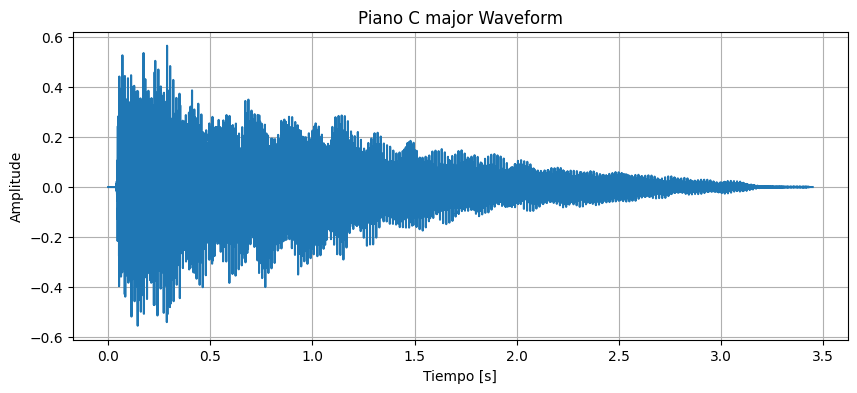

In [3]:
t = np.arange(len(signal)) / sr # tiempo transcurrido entre cada muestra
plt.figure(figsize=(10, 4))
plt.plot(t, signal)
plt.grid()
plt.title('Piano C major Waveform')
plt.xlabel('Tiempo [s]') 
plt.ylabel('Amplitude')
plt.show()

### 1. FFT con NumPy y SciPy

La FFT permite ver las frecuencias que componen el sonido. Como el resultado tiene frecuencias positivas y negativas, para identificar los tonos mostramos también solo la mitad positiva del espectro.

In [4]:
N = signal.shape[0]
amplitud = fft(signal)
frecuencia = fftfreq(N, 1/sr)

# Frecuencias Positivas (Plus)
amplitud_real = (2/N)*np.abs(amplitud)  
filtro = frecuencia >=  0 
amplitud_real = amplitud_real[filtro]
frecuencia_plus = frecuencia[filtro]

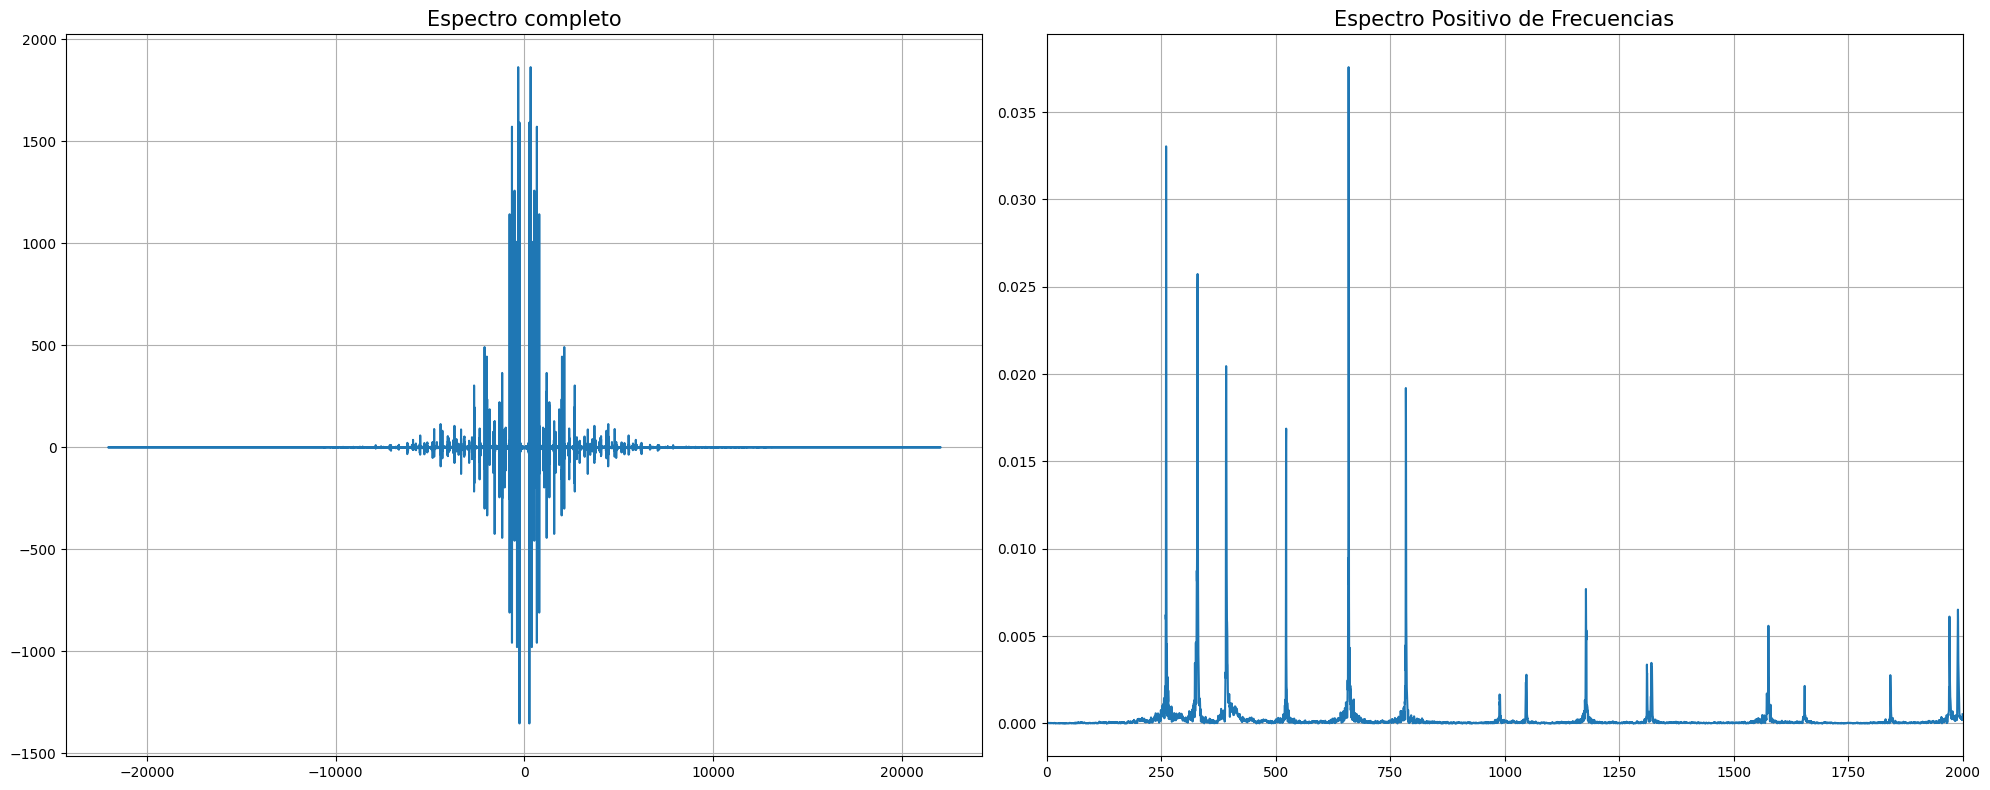

In [5]:
fig, ax  = plt.subplots(1,2, figsize=(20,8))

ax[0].set_title("Espectro completo", fontsize = 15)
ax[0].plot(frecuencia, amplitud)
ax[0].grid(True)

ax[1].set_title("Espectro Positivo de Frecuencias", fontsize = 15)
ax[1].plot(frecuencia_plus, amplitud_real)
ax[1].grid(True)
ax[1].set_xlim(0,2000)

plt.tight_layout()
plt.show()
warnings.filterwarnings('ignore', category=ComplexWarning)

### 2. Transformada usando la rutina FT(x,y) de clase

En clase la rutina usa la función base

$$g(t,w)=\frac{1}{2\pi}e^{-i2\pi wt}.$$



In [6]:
# Base Continua de la Fourier
def g(t,w):
    return 1./(2*np.pi)*np.exp(-1j*2*np.pi*w*t)

In [7]:
#  FT  para datos discretos
def FT(x,y,w):
    dx = x[1]-x[0]
    df = []
    for i in range(len(w)):
        Fw = np.sum(y*g(x,w[i]))*dx
        ARew = Fw.real
        AImw = Fw.imag
        AMP = np.sqrt(ARew**2 + AImw**2)
        ANG = np.arctan2(AImw,ARew)
        df.append([w[i], ARew, AImw, AMP, ANG])

    df = pd.DataFrame(df, columns=['w','ReTw','ImTw','AMP','ANG'])


    return df

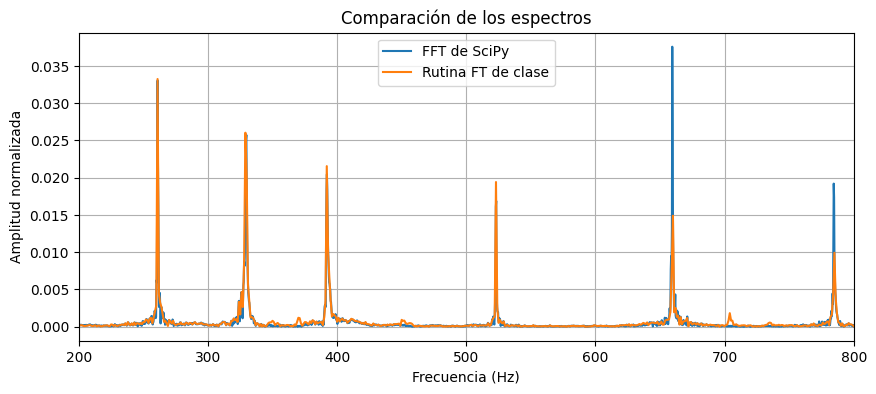

Picos de la rutina FT:
261.0 Hz -> 0.033243
329.0 Hz -> 0.026036
392.0 Hz -> 0.02155
523.0 Hz -> 0.019418
660.0 Hz -> 0.014894
785.0 Hz -> 0.009923
704.0 Hz -> 0.001824
370.0 Hz -> 0.0012
671.0 Hz -> 0.001173


In [8]:

factor = 10
x_FT = t[::factor]
y_FT = signal[::factor]
w = np.linspace(200,800,601)

df = FT(x_FT, y_FT, w)

# Ajustar la escala para comparar con el espectro normalizado de la FFT
dt = x_FT[1]-x_FT[0]
df['AMP_norm'] = df.AMP*4*np.pi/(len(y_FT)*dt)

plt.figure(figsize=(10,4))
plt.plot(frecuencia_plus, amplitud_real, label='FFT de SciPy')
plt.plot(df.w, df.AMP_norm, label='Rutina FT de clase')
plt.xlim(200,800)
plt.title('Comparación de los espectros')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Amplitud normalizada')
plt.legend()
plt.grid()
plt.show()

picos_FT, propiedades_FT = find_peaks(df.AMP_norm, prominence=np.max(df.AMP_norm)*0.02, height=np.max(df.AMP_norm)*0.03, distance=10)
orden_FT = np.argsort(df.AMP_norm.values[picos_FT])[::-1]
print('Picos de la rutina FT:')
for i in orden_FT[:10]:
    print(round(df.w.values[picos_FT[i]],2), 'Hz ->', round(df.AMP_norm.values[picos_FT[i]],6))

**Conclusión del ejemplo:** 
Tanto NumPy como SciPy generan resultados idénticos al calcular la FFT. Por su parte, la rutina personalizada FT identifica con precisión los picos en las mismas frecuencias; las ligeras variaciones en las amplitudes se deben al uso de una suma discreta aproximada, un menor número de muestras y la escala de normalización aplicada para comparar los espectros.

## **Exercise 1** : Do the FFT for an Imagen

Choose an Imagen





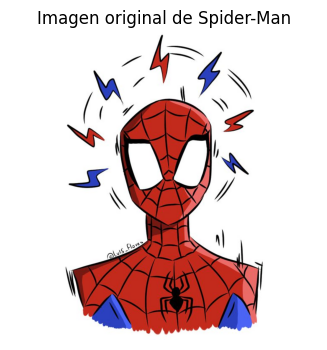

Tamaño de la matriz de la imagen: (96, 96)


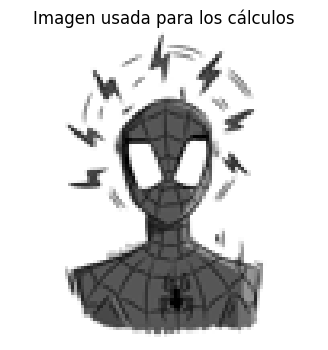

In [9]:
imagen_color = Image.open(r"C:\Users\Jean Salazar\Downloads\imagen_spiderman.jpg").convert('RGB')
plt.figure(figsize=(8,4))
plt.imshow(imagen_color)
plt.title('Imagen original de Spider-Man')
plt.axis('off')
plt.show()

# Convertir a escala de grises y reducir el tamaño
imagen_gris = Image.open(r"C:\Users\Jean Salazar\Downloads\imagen_spiderman.jpg").convert('L')
imagen_gris = imagen_gris.resize((96,96))
imagen = np.array(imagen_gris, dtype=float)/255.0

print('Tamaño de la matriz de la imagen:', imagen.shape)
plt.figure(figsize=(4,4))
plt.imshow(imagen, cmap='gray')
plt.title('Imagen usada para los cálculos')
plt.axis('off')
plt.show()

### 1. FFT de la imagen con SciPy

En una imagen, la transformada se aplica en dos dimensiones. La magnitud del espectro muestra cómo se distribuyen las frecuencias espaciales.

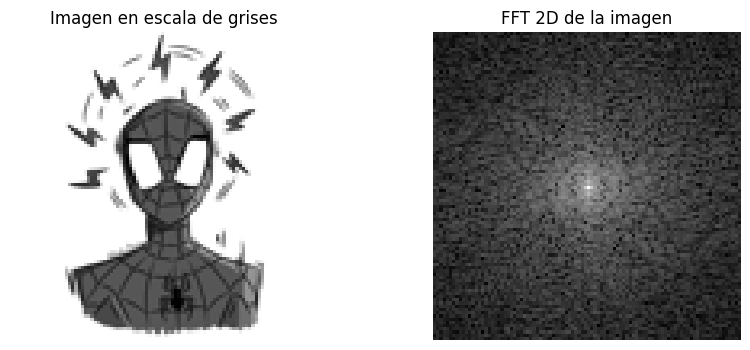

In [10]:
#  Fourier 2D con SciPy
F_scipy = fft2(imagen)
F_scipy_centro = fftshift(F_scipy)

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.imshow(imagen, cmap='gray')
plt.title('Imagen en escala de grises')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(np.log(1+np.abs(F_scipy_centro)), cmap='gray')
plt.title('FFT 2D de la imagen')
plt.axis('off')
plt.show()


### 2. Transformada de Fourier usando la rutina de clase

Para aplicarla a la imagen se hace la transformada de cada fila y después la de cada columna. Es la misma rutina FT(x,y,w), aplicada dos veces. La función "g" de clase tiene el factor 1/(2*pi), por lo que al comparar con fft2 se compensa ese factor en las dos dimensiones.

Error relativo entre FT de clase y SciPy: 2.417756246107752e-15


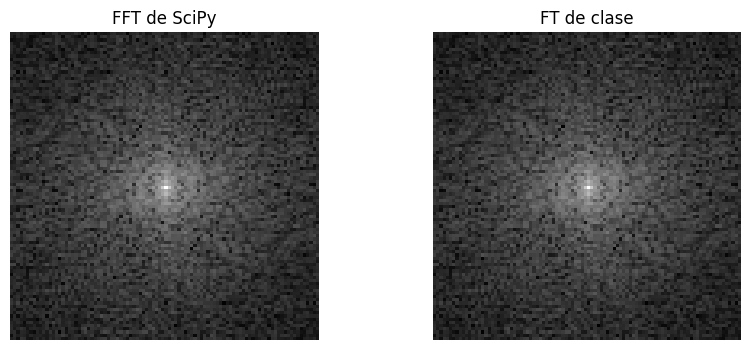

In [11]:
def FT2D(im):
    Nx, Ny = im.shape
    x = np.arange(Nx)
    y = np.arange(Ny)
    wx = np.fft.fftfreq(Nx, d=1)
    wy = np.fft.fftfreq(Ny, d=1)

    F1 = np.zeros((Nx,Ny), dtype=complex)
    for i in range(Nx):
        df_fila = FT(y, im[i,:], wy)
        F1[i,:] = df_fila.ReTw.values + 1j*df_fila.ImTw.values

    F2 = np.zeros((Nx,Ny), dtype=complex)
    for j in range(Ny):
        df_columna = FT(x, F1[:,j], wx)
        F2[:,j] = df_columna.ReTw.values + 1j*df_columna.ImTw.values

    return F2

F_clase = FT2D(imagen)




F_clase_comparar = F_clase*(2*np.pi)**2
error_relativo = np.max(np.abs(F_clase_comparar-F_scipy))/np.max(np.abs(F_scipy))
print('Error relativo entre FT de clase y SciPy:', error_relativo)

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.imshow(np.log(1+np.abs(fftshift(F_scipy))), cmap='gray')
plt.title('FFT de SciPy')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(np.log(1+np.abs(fftshift(F_clase_comparar))), cmap='gray')
plt.title('FT de clase')
plt.axis('off')
plt.show()

### 3. Transformada inversa y reconstrucción

Se aplica la transformada inversa a la FFT calculada con SciPy y comparamos

Error máximo: 8.881784197001252e-16
Error medio: 1.7919151405754175e-16


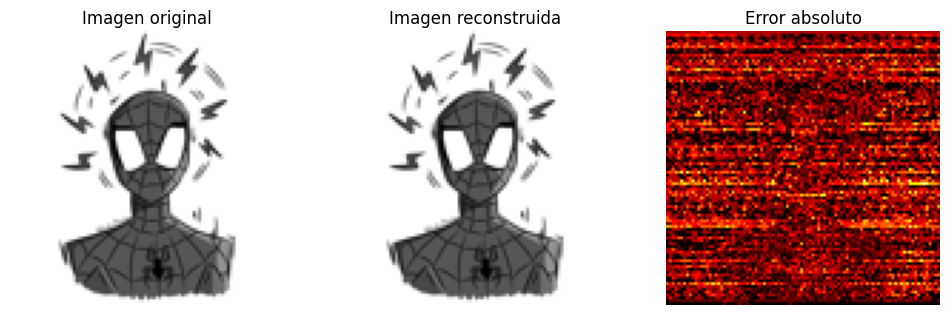

In [12]:

imagen_recuperada = ifft2(F_scipy).real
error = np.abs(imagen-imagen_recuperada)

print('Error máximo:', np.max(error))
print('Error medio:', np.mean(error))

plt.figure(figsize=(12,4))
plt.subplot(1,3,1)
plt.imshow(imagen, cmap='gray', vmin=0, vmax=1)
plt.title('Imagen original')
plt.axis('off')

plt.subplot(1,3,2)
plt.imshow(imagen_recuperada, cmap='gray', vmin=0, vmax=1)
plt.title('Imagen reconstruida')
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(error, cmap='hot')
plt.title('Error absoluto')
plt.axis('off')
plt.show()

**Conclusión del ejercicio:** 
Se observa una distribución espectral equivalente entre la implementación de clase y la librería SciPy tras homologar la normalización. La aplicación de la transformada inversa de Fourier reconstruye fielmente la matriz de entrada ($96 \times 96$ en escala de grises) con un margen de error numérico despreciable.